In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
# Same gradients for both methods
gradients = np.array([4, 4, -2, -2, 1, -1, 3, 3])

learning_rate = 0.1
beta = 0.9
initial_weight = 10
velocity = 0.0          # Initial momentum velocity

In [12]:
# Store weights after each update

sgd_weights = [initial_weight]          # 10
momentum_weights = [initial_weight]     # 10

In [13]:
for gradient in gradients:
    # ORDINARY SGD
    new_sgd_weights = (sgd_weights[-1] - learning_rate * gradient)
    sgd_weights.append(new_sgd_weights)

    # SGD with momentum
    velocity = beta * velocity + gradient
    new_momentum_weight = (momentum_weights[-1] - learning_rate * velocity)
    momentum_weights.append(new_momentum_weight)

In [14]:
print(sgd_weights)

[10, np.float64(9.6), np.float64(9.2), np.float64(9.399999999999999), np.float64(9.599999999999998), np.float64(9.499999999999998), np.float64(9.599999999999998), np.float64(9.299999999999997), np.float64(8.999999999999996)]


In [16]:
momentum_weights

[10,
 np.float64(9.6),
 np.float64(8.84),
 np.float64(8.356),
 np.float64(8.1204),
 np.float64(7.80836),
 np.float64(7.627524),
 np.float64(7.1647716),
 np.float64(6.44829444)]

### Display Results

In [17]:
print("Step | Gradient | Ordinary SGD | SGD with Momentum")
print("-" * 56)

for step in range(len(gradients) + 1):
    gradient = "-" if step == 0 else gradients[step - 1]
    print(
        f"{step:4} | {str(gradient):8} | "
        f"{sgd_weights[step]:12.3f} | "
        f"{momentum_weights[step]:17.3f}"
    )

Step | Gradient | Ordinary SGD | SGD with Momentum
--------------------------------------------------------
   0 | -        |       10.000 |            10.000
   1 | 4        |        9.600 |             9.600
   2 | 4        |        9.200 |             8.840
   3 | -2       |        9.400 |             8.356
   4 | -2       |        9.600 |             8.120
   5 | 1        |        9.500 |             7.808
   6 | -1       |        9.600 |             7.628
   7 | 3        |        9.300 |             7.165
   8 | 3        |        9.000 |             6.448


# Plot Weight updates

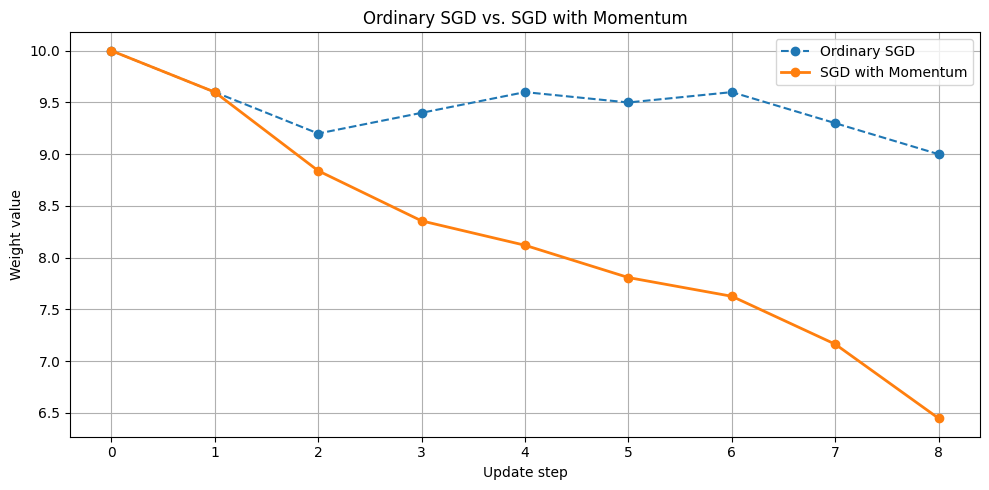

In [18]:
steps = np.arange(len(sgd_weights))

plt.figure(figsize=(10, 5))
plt.plot(
    steps, sgd_weights,
    marker="o", linestyle="--",
    label="Ordinary SGD"
)
plt.plot(
    steps, momentum_weights,
    marker="o", linewidth=2,
    label="SGD with Momentum"
)

plt.xlabel("Update step")
plt.ylabel("Weight value")
plt.title("Ordinary SGD vs. SGD with Momentum")
plt.xticks(steps)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()